# Pengembangan Sistem Peramalan Konsentrasi Polutan PM2.5 Berbasis Machine Learning untuk Early Warning Kualitas Udara di Kota Padang

**Mata Kuliah:** Machine Learning  |  **Tugas:** Tugas Besar  |  **Kelompok:** 7

**Anggota:**
1. Lyvia Putri Lestari (2411521006)
2. Febiola Ramli (2411521008)
3. Nasywa Hasanah Herida (2411521011)

**Versi 4 (Progress Report 2):** peramalan PM2.5 untuk **1 sampai 6 jam ke depan** (t+1, t+2, ..., t+6) dengan fitur polutan dan fitur cuaca, disertai alarm peringatan dini dengan probabilitas terkalibrasi.

---
## Alur notebook

| Bagian | Isi |
|---|---|
| 1 | Load `dataset.csv` (polutan) dan `cuaca.csv` (cuaca), gabung berdasarkan `time` |
| 2 | EDA polutan dan hubungan cuaca dengan PM2.5 |
| 3 | Rekayasa fitur di `fitur.py` (89 fitur polutan + 30 fitur cuaca) |
| 4 | Pembagian data dan TimeSeriesSplit (`gap=6`) |
| 5 | Baseline, pemilihan jumlah fitur, model XGBoost, dan perbandingan dengan/tanpa cuaca |
| 6 | Evaluasi akhir pada data test |
| 7 | Alarm Waspada: klasifier terkalibrasi dengan ambang dari data out-of-fold |
| 8 | Pelatihan ulang pada seluruh data dan penyimpanan `.joblib` |
| 9 | Uji integrasi sistem (untuk dashboard Streamlit) |
| 10 | Ringkasan hasil untuk laporan |

## 1. Setup & Load Data

In [1]:
!pip install -q xgboost joblib

# Dasar
import os, sys, glob, time, warnings
import numpy as np
import pandas as pd
import joblib

# Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Pemodelan
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import calibration_curve
from xgboost import XGBRegressor, XGBClassifier

# Evaluasi
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             average_precision_score, precision_recall_curve,
                             precision_score, recall_score, brier_score_loss)

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 3.5)

In [2]:
# Clone repo (dataset.csv = polutan, cuaca.csv = cuaca)
!rm -rf AirQuality
!git clone -q https://github.com/LyviaPutri/AirQuality.git

PATH_POLUTAN = 'AirQuality/dataset.csv'
PATH_CUACA   = 'AirQuality/cuaca.csv'
print('File CSV :', sorted(glob.glob('AirQuality/**/*.csv', recursive=True)))

File CSV : ['AirQuality/cuaca.csv', 'AirQuality/dataset.csv']


In [3]:
def baca_openmeteo(path, rename):
    """Baca CSV Open-Meteo: lewati baris metadata otomatis (cari baris header 'time')."""
    with open(path, encoding='utf-8') as f:
        skip = next(i for i, line in enumerate(f) if line.startswith('time'))
    d = pd.read_csv(path, skiprows=skip)
    d.columns = [c.split(' (')[0] for c in d.columns]      # buang satuan di nama kolom
    d = d.rename(columns=rename)
    d['time'] = pd.to_datetime(d['time'])
    return d.set_index('time').sort_index()

polutan = baca_openmeteo(PATH_POLUTAN, {'carbon_monoxide': 'co', 'nitrogen_dioxide': 'no2',
                                        'sulphur_dioxide': 'so2', 'ozone': 'o3'})
cuaca = baca_openmeteo(PATH_CUACA, {'temperature_2m': 'temp', 'relative_humidity_2m': 'rh',
                                    'precipitation': 'hujan', 'wind_speed_10m': 'angin',
                                    'wind_direction_10m': 'arah_angin', 'surface_pressure': 'tekanan'})
print('Polutan:', polutan.shape, '| kolom:', list(polutan.columns))
print('Cuaca  :', cuaca.shape,   '| kolom:', list(cuaca.columns))

# Gabung berdasarkan waktu (inner join) lalu cek ulang
df = polutan.join(cuaca, how='inner')
assert len(df) == len(polutan) == len(cuaca), 'Jumlah baris tidak sama setelah digabung'
assert df.index.is_unique and df.index.is_monotonic_increasing
print('\nGabungan:', df.shape)
print('Total nilai kosong :', int(df.isna().sum().sum()))
print('Jam hilang         :', len(pd.date_range(df.index.min(), df.index.max(), freq='h')) - len(df))
df.head()

Polutan: (35064, 6) | kolom: ['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3']
Cuaca  : (35064, 6) | kolom: ['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']

Gabungan: (35064, 12)
Total nilai kosong : 0
Jam hilang         : 0


,pm10,pm2_5,co,no2,so2,o3,temp,rh,hujan,angin,arah_angin,tekanan
time,,,,,,,,,,,,
2022-09-01 00:00:00,34.9,24.2,869.0,32.0,2.2,27.0,24.3,90,0.0,2.8,40,1008.1
2022-09-01 01:00:00,29.1,20.1,718.0,28.2,1.7,26.0,23.7,92,0.0,3.1,69,1007.2
2022-09-01 02:00:00,25.7,17.6,644.0,24.6,1.5,26.0,24.0,89,0.0,2.7,23,1007.3
2022-09-01 03:00:00,25.3,17.3,578.0,20.3,1.4,27.0,23.2,98,1.2,3.2,27,1007.5
2022-09-01 04:00:00,26.4,18.0,513.0,15.6,1.3,29.0,23.8,92,0.9,10.3,78,1006.5


> **Catatan lokasi.** Koordinat polutan (-0.9000, 100.3999, elevasi 49 m) dan cuaca (-0.8787, 100.4009, elevasi 19 m) berbeda sekitar **2,4 km** karena tiap API memakai grid model yang berbeda. Cuaca di sini adalah pendekatan untuk kondisi di titik polutan, bukan pengukuran di titik yang sama. Ini dicatat sebagai keterbatasan di laporan.

## 2. Exploratory Data Analysis (EDA)

In [4]:
print('Rentang waktu :', df.index.min(), '->', df.index.max())
print('\nMissing value:\n', df.isna().sum())
df.describe().T

Rentang waktu : 2022-09-01 00:00:00 -> 2026-08-31 23:00:00

Missing value:
 pm10          0
pm2_5         0
co            0
no2           0
so2           0
o3            0
temp          0
rh            0
hujan         0
angin         0
arah_angin    0
tekanan       0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
pm10,35064.0,19.855493,10.189211,0.6,12.2,17.8,25.7,87.1
pm2_5,35064.0,15.598406,8.515466,0.4,9.5,13.6,19.7,85.7
co,35064.0,694.955025,564.195272,60.0,342.0,507.0,812.0,4820.0
no2,35064.0,10.582475,6.767393,0.0,5.1,9.5,14.9,51.3
so2,35064.0,6.537035,3.714666,0.2,3.7,6.1,8.9,25.7
o3,35064.0,50.175935,26.770106,3.0,30.0,43.0,66.0,182.0
temp,35064.0,26.073329,1.986927,19.8,24.5,25.7,27.5,32.8
rh,35064.0,85.759411,8.397149,48.0,81.0,87.0,92.0,100.0
hujan,35064.0,0.425950,1.299773,0.0,0.0,0.0,0.2,32.5
angin,35064.0,4.596441,2.517097,0.0,2.7,4.2,6.0,20.9


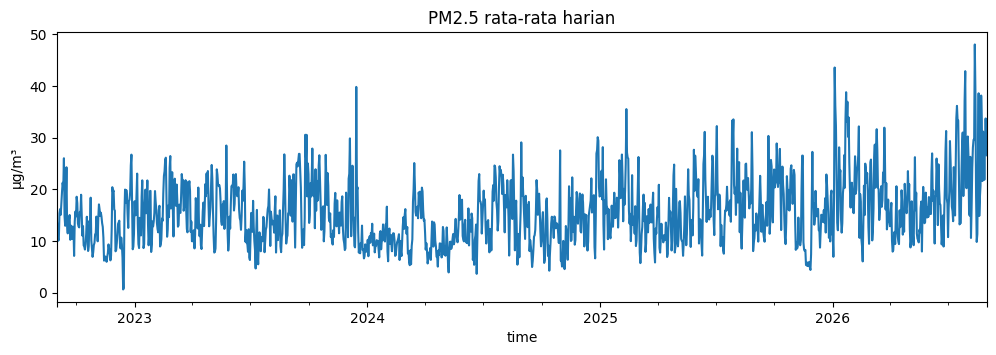

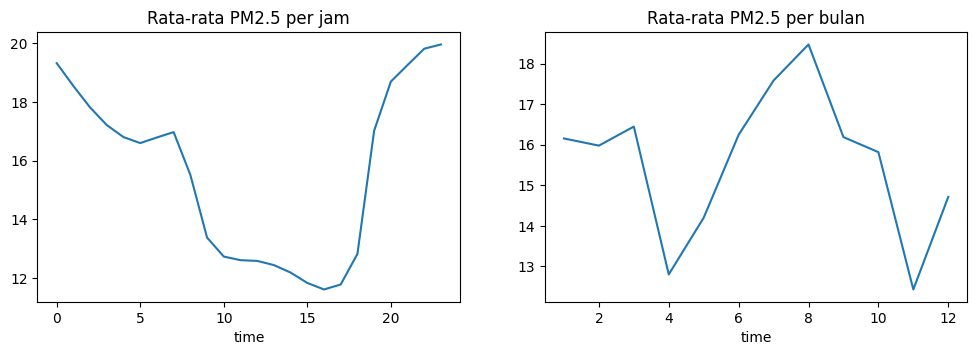

In [5]:
# Tren harian
df['pm2_5'].resample('D').mean().plot(title='PM2.5 rata-rata harian')
plt.ylabel('µg/m³'); plt.show()

# Pola per jam dan per bulan
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.groupby(df.index.hour)['pm2_5'].mean().plot(ax=ax[0], title='Rata-rata PM2.5 per jam')
df.groupby(df.index.month)['pm2_5'].mean().plot(ax=ax[1], title='Rata-rata PM2.5 per bulan')
plt.show()

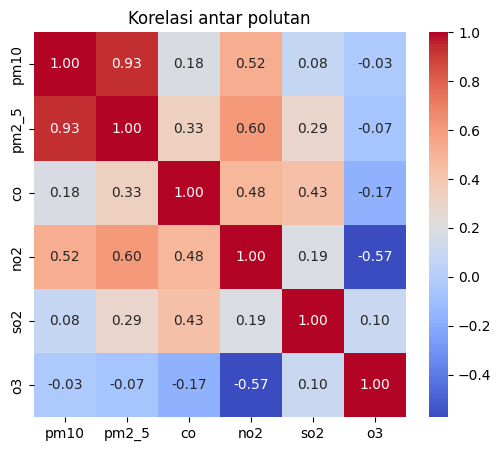

Korelasi PM2.5 dengan polutan lain:
pm10    0.93
co      0.33
no2     0.60
so2     0.29
o3     -0.07


In [6]:
# Korelasi antar polutan
plt.figure(figsize=(6, 5))
sns.heatmap(df[['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi antar polutan'); plt.show()

print('Korelasi PM2.5 dengan polutan lain:')
print(df[['pm10', 'co', 'no2', 'so2', 'o3']].corrwith(df['pm2_5']).round(2).to_string())

### 2.1 Hubungan cuaca dengan PM2.5

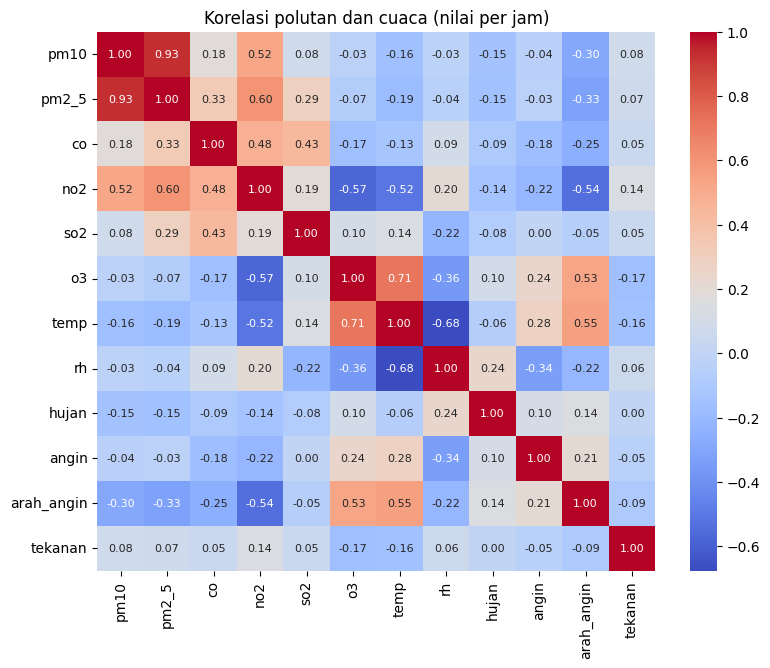

Korelasi PM2.5 dengan variabel cuaca:
temp         -0.189
rh           -0.042
hujan        -0.155
angin        -0.030
arah_angin   -0.329
tekanan       0.071


In [7]:
# Korelasi polutan + cuaca
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 8})
plt.title('Korelasi polutan dan cuaca (nilai per jam)'); plt.show()

print('Korelasi PM2.5 dengan variabel cuaca:')
print(df[['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']].corrwith(df['pm2_5']).round(3).to_string())

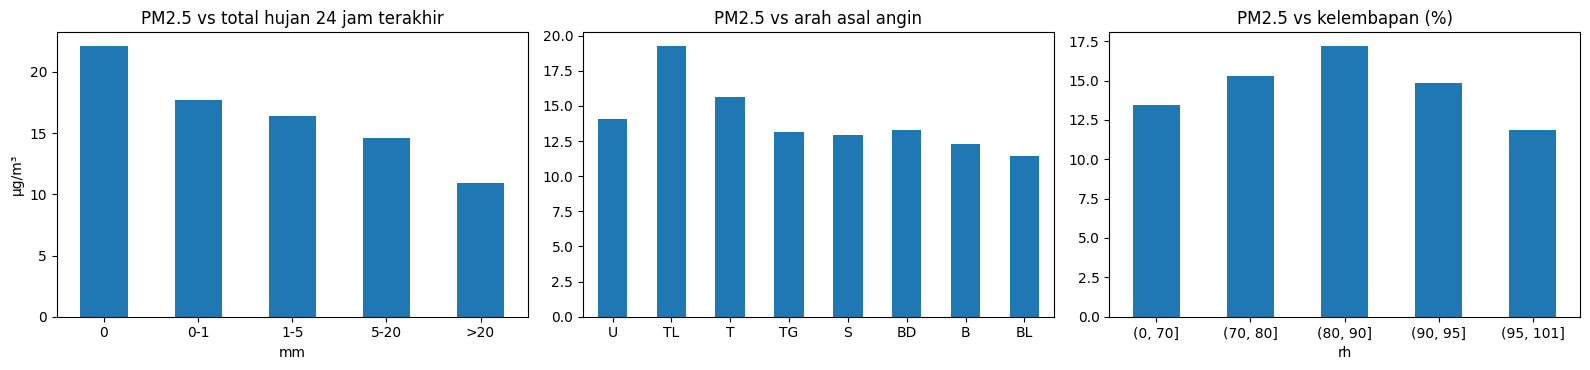

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))

# (a) Hujan 24 jam terakhir vs PM2.5 (hujan membersihkan partikel)
h24 = df['hujan'].rolling(24).sum()
kelas = pd.cut(h24, [-0.01, 0.0, 1, 5, 20, 1e9], labels=['0', '0-1', '1-5', '5-20', '>20'])
df.groupby(kelas)['pm2_5'].mean().plot.bar(ax=ax[0], rot=0, title='PM2.5 vs total hujan 24 jam terakhir')
ax[0].set_xlabel('mm'); ax[0].set_ylabel('µg/m³')

# (b) Arah angin vs PM2.5 (8 sektor)
sektor = ((df['arah_angin'] + 22.5) // 45 % 8).astype(int)
nama = ['U', 'TL', 'T', 'TG', 'S', 'BD', 'B', 'BL']
g = df.groupby(sektor)['pm2_5'].mean(); g.index = [nama[i] for i in g.index]
g.plot.bar(ax=ax[1], rot=0, title='PM2.5 vs arah asal angin')

# (c) Kelembapan vs PM2.5
kelas_rh = pd.cut(df['rh'], [0, 70, 80, 90, 95, 101])
df.groupby(kelas_rh)['pm2_5'].mean().plot.bar(ax=ax[2], rot=0, title='PM2.5 vs kelembapan (%)')
plt.tight_layout(); plt.show()

## 3. Data Processing Procedures & Feature Engineering
Prosedur dibuat sebagai fungsi di `fitur.py`, sehingga **identik** dipakai saat pelatihan dan saat prediksi di sistem (Streamlit).

**Fitur polutan (89):** nilai sekarang dan lag (t-1 sampai t-168 jam) untuk 6 polutan, statistik bergulir PM2.5, rata-rata 24 jam polutan lain, selisih dan EWM PM2.5, rasio PM2.5/PM10, serta fitur waktu siklik.

**Fitur cuaca (30):**

| Kelompok | Fitur | Jumlah |
|---|---|---|
| Suhu, kelembapan, tekanan, angin | nilai pada t, t-1, t-3, t-6, t-24 | 4 × 5 = 20 |
| Hujan | nilai pada t + total 6, 24, 72 jam terakhir | 4 |
| Arah angin | sin, cos, serta komponen u dan v (kecepatan × arah) | 4 |
| Tren tekanan | selisih 3 jam dan 24 jam | 2 |

> **Aturan anti-kebocoran:** semua fitur (polutan maupun cuaca) hanya memakai informasi sampai jam **t**. Target adalah PM2.5 pada t+1, t+2, ..., t+6 jam.
>
> Arah angin diubah ke sin/cos karena 359° dan 1° itu berdekatan. Komponen u/v juga ikut karena arah angin tidak bermakna ketika kecepatan angin nyaris nol.

In [9]:
%%writefile fitur.py
import numpy as np
import pandas as pd

HORIZONS = [1, 2, 3, 4, 5, 6]   # jam ke depan
LAGS = [1, 2, 3, 6, 12, 24, 48, 72, 168]
POLUTAN = ['pm10', 'pm2_5', 'co', 'no2', 'so2', 'o3']
CUACA = ['temp', 'rh', 'hujan', 'angin', 'arah_angin', 'tekanan']
CUACA_LAGS = [1, 3, 6, 24]
HUJAN_WINDOW = [6, 24, 72]
MIN_RIWAYAT = 200   # jam riwayat minimal untuk membentuk satu baris fitur


def fitur_polutan(d):
    """89 fitur dari data polutan (hanya memakai informasi sampai jam t)."""
    f = {}
    for c in POLUTAN:
        f[f'{c}_now'] = d[c]
        for l in LAGS:
            f[f'{c}_lag{l}'] = d[c].shift(l)

    pm = d['pm2_5']
    pm_s = pm.shift(1)
    for w in [6, 24, 72, 168]:
        f[f'pm2_5_rmean{w}'] = pm_s.rolling(w).mean()
        f[f'pm2_5_rstd{w}'] = pm_s.rolling(w).std()
    for w in [24, 72]:
        f[f'pm2_5_rmax{w}'] = pm_s.rolling(w).max()
        f[f'pm2_5_rmin{w}'] = pm_s.rolling(w).min()
    for c in ['pm10', 'co', 'no2', 'so2', 'o3']:
        f[f'{c}_rmean24'] = d[c].shift(1).rolling(24).mean()

    for k in [1, 3, 6, 24]:
        f[f'pm2_5_diff{k}'] = pm - pm.shift(k)
    f['pm2_5_ewm6'] = pm_s.ewm(span=6).mean()
    f['pm2_5_ewm24'] = pm_s.ewm(span=24).mean()
    f['pm_ratio'] = pm / (d['pm10'] + 1e-6)

    idx = d.index
    f['hour_sin'] = np.sin(2 * np.pi * idx.hour.values / 24)
    f['hour_cos'] = np.cos(2 * np.pi * idx.hour.values / 24)
    f['month_sin'] = np.sin(2 * np.pi * idx.month.values / 12)
    f['month_cos'] = np.cos(2 * np.pi * idx.month.values / 12)
    f['dayofweek'] = idx.dayofweek.values
    return pd.DataFrame(f, index=d.index)


def fitur_cuaca(d):
    """30 fitur dari data cuaca (hanya memakai informasi sampai jam t)."""
    f = {}
    for c in ['temp', 'rh', 'tekanan', 'angin']:
        f[f'{c}_now'] = d[c]
        for l in CUACA_LAGS:
            f[f'{c}_lag{l}'] = d[c].shift(l)

    # Hujan: akumulasi lebih informatif daripada nilai per jam
    h = d['hujan']
    f['hujan_now'] = h
    for w in HUJAN_WINDOW:
        f[f'hujan_sum{w}'] = h.rolling(w).sum()

    # Arah angin: sin/cos (siklik) dan komponen u, v (dikali kecepatan)
    rad = np.deg2rad(d['arah_angin'])
    f['arah_sin'] = np.sin(rad)
    f['arah_cos'] = np.cos(rad)
    f['wind_u'] = -d['angin'] * np.sin(rad)
    f['wind_v'] = -d['angin'] * np.cos(rad)

    # Tren tekanan
    f['tekanan_diff3'] = d['tekanan'] - d['tekanan'].shift(3)
    f['tekanan_diff24'] = d['tekanan'] - d['tekanan'].shift(24)
    return pd.DataFrame(f, index=d.index)


def buat_fitur(d):
    """Tabel fitur lengkap (119 fitur: 89 polutan + 30 cuaca). Dipakai pelatihan dan dashboard."""
    return pd.concat([fitur_polutan(d), fitur_cuaca(d)], axis=1)


class Kalibrator:
    """Kalibrasi probabilitas dengan isotonic regression. Disimpan di fitur.py agar
    model .joblib bisa dimuat dashboard (joblib perlu menemukan kelas ini)."""
    def fit(self, p, y):
        from sklearn.isotonic import IsotonicRegression
        self.m = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(
            np.asarray(p, dtype=float), np.asarray(y))
        return self

    def predict(self, p):
        return self.m.predict(np.asarray(p, dtype=float))

Writing fitur.py


In [10]:
sys.modules.pop('fitur', None)   # muat ulang fitur.py kalau baru diubah
from fitur import (buat_fitur, fitur_polutan, fitur_cuaca, Kalibrator,
                   HORIZONS, POLUTAN, CUACA, MIN_RIWAYAT)

feat = buat_fitur(df)
targets = pd.DataFrame({f'y_{h}h': df['pm2_5'].shift(-h) for h in HORIZONS})

data = pd.concat([feat, targets], axis=1).dropna()
COLS_A = list(fitur_polutan(df).columns)          # fitur polutan saja (dipakai untuk perbandingan)
COLS_CUACA = list(fitur_cuaca(df).columns)
COLS_B = COLS_A + COLS_CUACA                      # fitur lengkap: polutan + cuaca (model final)
assert set(COLS_B) == set(c for c in data.columns if not c.startswith('y_'))

print('Dataset akhir :', data.shape)
print(f'Fitur polutan : {len(COLS_A)} | Fitur cuaca : {len(COLS_CUACA)} | Total : {len(COLS_B)}')
print(f'Baris hilang karena riwayat/target: {len(df) - len(data)}')

Dataset akhir : (34890, 125)
Fitur polutan : 89 | Fitur cuaca : 30 | Total : 119
Baris hilang karena riwayat/target: 174


## 4. Pembagian Data & Validasi Silang Deret Waktu
- **Data test (15% terakhir)** dipisahkan lebih dulu dan **tidak dipakai untuk tuning**.
- **Data development (85% awal)** dipakai untuk pemilihan fitur dengan **TimeSeriesSplit (walk-forward, 5 fold)**: train selalu di masa lalu, validasi di masa setelahnya.
- `gap` = horizon terjauh (**6 jam**) dibuang di antara train dan validasi karena target berupa nilai t+h, sehingga tidak ada tumpang tindih informasi.
- K-Fold biasa (acak) **tidak dipakai** karena merusak struktur autokorelasi dan membocorkan informasi masa depan.

In [11]:
n = len(data)
dev  = data.iloc[:int(n * 0.85)]     # untuk CV + pelatihan
test = data.iloc[int(n * 0.85):]     # tetap murni sampai evaluasi akhir

GAP = max(HORIZONS)
tscv = TimeSeriesSplit(n_splits=5, gap=GAP)
folds = list(tscv.split(dev))

print(f'Dev : {dev.index.min()} -> {dev.index.max()} ({len(dev)} baris)')
print(f'Test: {test.index.min()} -> {test.index.max()} ({len(test)} baris)\n')
for i, (a, b) in enumerate(folds, 1):
    print(f'Fold {i}: train {dev.index[a[0]].date()} -> {dev.index[a[-1]].date()} ({len(a):>5}) | '
          f'val {dev.index[b[0]].date()} -> {dev.index[b[-1]].date()} ({len(b)})')

Dev : 2022-09-08 00:00:00 -> 2026-01-25 15:00:00 (29656 baris)
Test: 2026-01-25 16:00:00 -> 2026-08-31 17:00:00 (5234 baris)

Fold 1: train 2022-09-08 -> 2023-04-01 ( 4940) | val 2023-04-02 -> 2023-10-24 (4942)
Fold 2: train 2022-09-08 -> 2023-10-24 ( 9882) | val 2023-10-25 -> 2024-05-17 (4942)
Fold 3: train 2022-09-08 -> 2024-05-17 (14824) | val 2024-05-17 -> 2024-12-09 (4942)
Fold 4: train 2022-09-08 -> 2024-12-09 (19766) | val 2024-12-09 -> 2025-07-03 (4942)
Fold 5: train 2022-09-08 -> 2025-07-03 (24708) | val 2025-07-03 -> 2026-01-25 (4942)


## 5. Baseline, Pemilihan Fitur & Model XGBoost

**Pembanding:** Persistence (nilai sekarang dianggap nilai nanti) dan Ridge Regression. **Model utama:** XGBoost Regressor, satu model per horizon (*direct multi-step*).

**Pemilihan jumlah fitur (K)** dilakukan dengan TimeSeriesSplit. Ranking fitur dihitung **di dalam tiap fold** (hanya dari data train fold) agar tidak ada kebocoran. Dipilih K **terkecil** yang RMSE CV-nya dalam 1% dari terbaik (prinsip parsimoni).

In [12]:
results = []
def rmse_f(a, b): return np.sqrt(mean_squared_error(a, b))

def evaluate(y_true, y_pred, model, h):
    results.append({'Horizon': h, 'Model': model,
                    'RMSE': rmse_f(y_true, y_pred),
                    'MAE': mean_absolute_error(y_true, y_pred),
                    'R2': r2_score(y_true, y_pred)})

# Baseline: Persistence dan Ridge (fitur lengkap)
for h in HORIZONS:
    y = f'y_{h}h'
    evaluate(test[y], test['pm2_5_now'], 'Persistence', h)
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(dev[COLS_B], dev[y])
    evaluate(test[y], ridge.predict(test[COLS_B]), 'Ridge (linear)', h)
print('Baseline selesai untuk', len(HORIZONS), 'horizon')

Baseline selesai untuk 6 horizon


### 5.1 Pemilihan jumlah fitur dengan TimeSeriesSplit

In [13]:
# Parameter untuk CV (tanpa early stopping agar perbandingan antar-K adil)
XGB_CV = dict(n_estimators=400, learning_rate=0.05, max_depth=3, min_child_weight=30,
              subsample=0.7, colsample_bytree=0.6, reg_lambda=30, reg_alpha=1.0, gamma=1.0,
              tree_method='hist', random_state=42, n_jobs=-1)
# Parameter model final (early stopping pada potongan terakhir data dev)
XGB_FINAL = {**XGB_CV, 'n_estimators': 3000, 'learning_rate': 0.03, 'early_stopping_rounds': 100}

VERSI = {'A': COLS_A, 'B': COLS_B}   # A = polutan saja, B = polutan + cuaca
K_BASE = [15, 30, 45]                # K = semua fitur ditambahkan otomatis per versi

# Cross-validation walk-forward. Versi A dihitung hanya untuk membandingkan kontribusi cuaca (bagian 5.3).
cv_rows = []
t0 = time.time()
for h in HORIZONS:
    y = f'y_{h}h'
    for v, pool in VERSI.items():
        K_GRID = K_BASE + [len(pool)]
        for fi, (a, b) in enumerate(folds, 1):
            tr, va = dev.iloc[a], dev.iloc[b]
            m_all = XGBRegressor(**XGB_CV).fit(tr[pool], tr[y])          # sekaligus untuk ranking & K=semua
            urut = pd.Series(m_all.feature_importances_, index=pool).sort_values(ascending=False)
            for K in K_GRID:
                if K == len(pool):
                    pred = m_all.predict(va[pool])
                else:
                    cols = list(urut.index[:K])
                    pred = XGBRegressor(**XGB_CV).fit(tr[cols], tr[y]).predict(va[cols])
                cv_rows.append({'Versi': v, 'Horizon': h, 'K': K, 'Fold': fi, 'RMSE': rmse_f(va[y], pred)})
    print(f't+{h}h selesai | {time.time() - t0:.0f} dtk')
cv_fold = pd.DataFrame(cv_rows)
cv_df = (cv_fold.groupby(['Versi', 'Horizon', 'K'])['RMSE']
         .agg(['mean', 'std']).rename(columns={'mean': 'CV RMSE (mean)', 'std': 'CV RMSE (std)'}).reset_index())

t+1h selesai | 85 dtk
t+2h selesai | 149 dtk
t+3h selesai | 215 dtk
t+4h selesai | 282 dtk
t+5h selesai | 360 dtk
t+6h selesai | 425 dtk


### 5.2 Pelatihan model final per horizon

In [14]:
def pilih_K(v, h):
    """K terkecil yang RMSE CV-nya dalam 1% dari terbaik."""
    g = cv_df[(cv_df.Versi == v) & (cv_df.Horizon == h)]
    best = g['CV RMSE (mean)'].min()
    return int(g[g['CV RMSE (mean)'] <= best * 1.01]['K'].min())

cut = int(len(dev) * 0.85)
fit_part, es_part = dev.iloc[:cut - GAP], dev.iloc[cut:]       # es_part = validasi early stopping

models = {'A': {}, 'B': {}}
for h in HORIZONS:
    y = f'y_{h}h'
    for v, pool in VERSI.items():
        K = pilih_K(v, h)
        urut = pd.Series(XGBRegressor(**XGB_CV).fit(dev[pool], dev[y]).feature_importances_,
                         index=pool).sort_values(ascending=False)
        cols = list(urut.index[:K])
        m = XGBRegressor(**XGB_FINAL)
        m.fit(fit_part[cols], fit_part[y], eval_set=[(es_part[cols], es_part[y])], verbose=False)
        models[v][h] = {'XGBoost': m, 'features': cols, 'K': K}
    evaluate(test[y], models['A'][h]['XGBoost'].predict(test[models['A'][h]['features']]), 'XGB polutan saja', h)
    evaluate(test[y], models['B'][h]['XGBoost'].predict(test[models['B'][h]['features']]), 'XGBoost (final)', h)
    print(f't+{h}h | K polutan saja={models["A"][h]["K"]:>3} | K final={models["B"][h]["K"]:>3} | '
          f'iterasi terbaik={models["B"][h]["XGBoost"].best_iteration}')

final_models = models['B']      # model final: polutan + cuaca untuk semua horizon

t+1h | K polutan saja= 15 | K final= 30 | iterasi terbaik=1157
t+2h | K polutan saja= 15 | K final= 30 | iterasi terbaik=1624
t+3h | K polutan saja= 30 | K final= 45 | iterasi terbaik=884
t+4h | K polutan saja= 30 | K final= 45 | iterasi terbaik=848
t+5h | K polutan saja= 89 | K final= 45 | iterasi terbaik=971
t+6h | K polutan saja= 30 | K final= 45 | iterasi terbaik=713


In [15]:
# Hasil CV model final: RMSE rata-rata antar-fold untuk tiap jumlah fitur K
tabel = cv_df[cv_df.Versi == 'B'].pivot(index='Horizon', columns='K', values='CV RMSE (mean)').round(3)
tabel['K terpilih'] = [final_models[h]['K'] for h in HORIZONS]
print('CV RMSE (mean antar 5 fold) per jumlah fitur K, model final:')
display(tabel)

# Cek overfitting: RMSE dev (train) vs CV vs test
rows = []
for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']; m = final_models[h]['XGBoost']
    tr_r = rmse_f(dev[y], m.predict(dev[cols])); te_r = rmse_f(test[y], m.predict(test[cols]))
    cvm = cv_df[(cv_df.Versi == 'B') & (cv_df.Horizon == h) & (cv_df.K == final_models[h]['K'])]['CV RMSE (mean)'].iloc[0]
    rows.append({'Horizon': h, 'Dev (train)': tr_r, 'CV (mean)': cvm, 'Test': te_r, 'Gap (Test-Dev)': te_r - tr_r})
print('Cek overfitting: RMSE dev (train) vs CV vs test')
display(pd.DataFrame(rows).set_index('Horizon').round(3))

CV RMSE (mean antar 5 fold) per jumlah fitur K, model final:


K,15,30,45,119,K terpilih
Horizon,,,,,
1,2.137,2.090,2.101,2.120,30
2,3.169,3.091,3.067,3.097,30
3,3.892,3.808,3.767,3.812,45
4,4.495,4.398,4.354,4.338,45
5,5.083,4.860,4.842,4.798,45
6,5.437,5.251,5.179,5.154,45


Cek overfitting: RMSE dev (train) vs CV vs test


,Dev (train),CV (mean),Test,Gap (Test-Dev)
Horizon,,,,
1,1.775,2.090,3.162,1.387
2,2.520,3.091,4.617,2.097
3,3.155,3.767,5.620,2.465
4,3.608,4.354,6.390,2.782
5,3.965,4.842,7.065,3.099
6,4.346,5.179,7.521,3.175


### 5.3 Kontribusi fitur cuaca
Model dengan **fitur polutan saja (A)** dibandingkan dengan **polutan + cuaca (B)** memakai pipeline yang persis sama (parameter, TimeSeriesSplit, seleksi K di dalam fold). Model final memakai B untuk semua horizon karena dashboard tetap membutuhkan data cuaca.

In [16]:
rows = []
for h in HORIZONS:
    y = f'y_{h}h'
    fa = cv_fold[(cv_fold.Versi == 'A') & (cv_fold.Horizon == h) & (cv_fold.K == models['A'][h]['K'])].sort_values('Fold')['RMSE'].values
    fb = cv_fold[(cv_fold.Versi == 'B') & (cv_fold.Horizon == h) & (cv_fold.K == models['B'][h]['K'])].sort_values('Fold')['RMSE'].values
    te_a = rmse_f(test[y], models['A'][h]['XGBoost'].predict(test[models['A'][h]['features']]))
    te_b = rmse_f(test[y], models['B'][h]['XGBoost'].predict(test[models['B'][h]['features']]))
    rows.append({'Horizon': h,
                 'CV A (mean)': fa.mean(), 'CV A (std)': fa.std(ddof=1),
                 'CV B (mean)': fb.mean(), 'CV B (std)': fb.std(ddof=1),
                 'Fold B menang': f'{int((fb < fa).sum())}/5',
                 'Test A': te_a, 'Test B': te_b, 'Selisih test (B-A)': te_b - te_a,
                 'Perbaikan test (%)': 100 * (te_a - te_b) / te_a})
ablation = pd.DataFrame(rows).set_index('Horizon')
display(ablation.round(3))

n_cv = int((ablation['CV B (mean)'] < ablation['CV A (mean)']).sum())
n_te = int((ablation['Selisih test (B-A)'] < 0).sum())
print(f'Fitur cuaca (B) lebih baik di CV pada {n_cv}/{len(HORIZONS)} horizon dan di test pada {n_te}/{len(HORIZONS)} horizon; '
      f"rata-rata perbaikan RMSE test = {ablation['Perbaikan test (%)'].mean():.1f}%")

,CV A (mean),CV A (std),CV B (mean),CV B (std),Fold B menang,Test A,Test B,Selisih test (B-A),Perbaikan test (%)
Horizon,,,,,,,,,
1,2.106,0.396,2.090,0.394,3/5,3.119,3.162,0.043,-1.367
2,3.148,0.590,3.091,0.534,4/5,4.708,4.617,-0.091,1.940
3,3.857,0.699,3.767,0.612,4/5,5.708,5.620,-0.088,1.544
4,4.448,0.827,4.354,0.722,3/5,6.480,6.390,-0.090,1.384
5,4.922,0.943,4.842,0.819,3/5,7.127,7.065,-0.062,0.869
6,5.347,1.059,5.179,0.918,4/5,7.614,7.521,-0.093,1.222


Fitur cuaca (B) lebih baik di CV pada 6/6 horizon dan di test pada 5/6 horizon; rata-rata perbaikan RMSE test = 0.9%


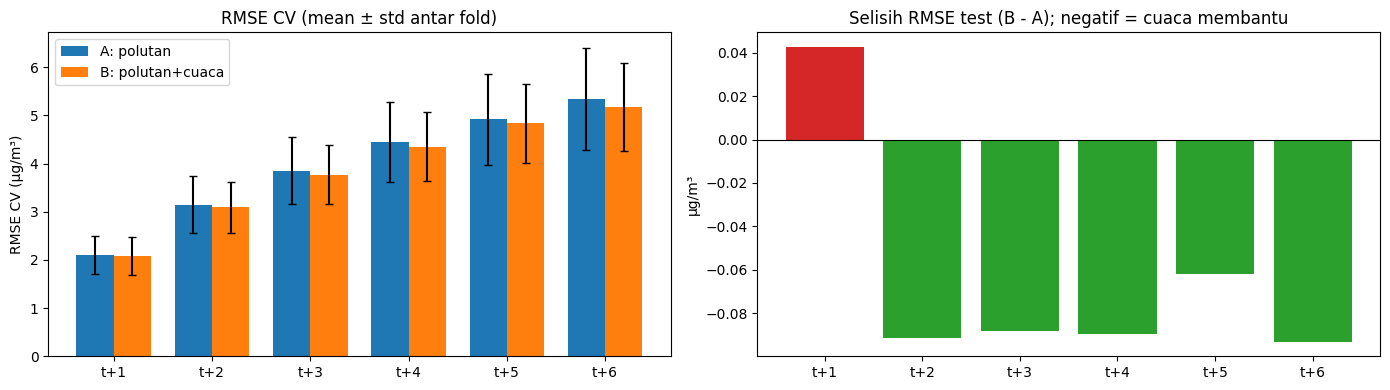

,Fitur cuaca terpilih,Porsi importance cuaca,Fitur cuaca teratas
Horizon,,,
1,1/30,0.004,temp_lag6
2,3/30,0.024,"temp_lag6, rh_lag1, temp_lag3"
3,9/45,0.068,"temp_lag6, hujan_now, rh_lag1"
4,11/45,0.108,"temp_lag6, rh_lag1, hujan_now"
5,8/45,0.112,"temp_lag3, temp_lag6, hujan_now"
6,10/45,0.154,"temp_lag3, temp_lag6, hujan_now"


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(HORIZONS)); w = 0.38
ax[0].bar(x - w/2, ablation['CV A (mean)'], w, yerr=ablation['CV A (std)'], capsize=3, label='A: polutan')
ax[0].bar(x + w/2, ablation['CV B (mean)'], w, yerr=ablation['CV B (std)'], capsize=3, label='B: polutan+cuaca')
ax[0].set_xticks(x); ax[0].set_xticklabels([f't+{h}' for h in HORIZONS]); ax[0].set_ylabel('RMSE CV (µg/m³)')
ax[0].set_title('RMSE CV (mean ± std antar fold)'); ax[0].legend()

ax[1].bar(x, ablation['Selisih test (B-A)'], color=['tab:green' if v < 0 else 'tab:red' for v in ablation['Selisih test (B-A)']])
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xticks(x); ax[1].set_xticklabels([f't+{h}' for h in HORIZONS])
ax[1].set_title('Selisih RMSE test (B - A); negatif = cuaca membantu'); ax[1].set_ylabel('µg/m³')
plt.tight_layout(); plt.show()

# Seberapa besar fitur cuaca dipakai model final (porsi importance)
rows = []
for h in HORIZONS:
    imp = pd.Series(final_models[h]['XGBoost'].feature_importances_, index=final_models[h]['features'])
    cu = imp[imp.index.isin(COLS_CUACA)]
    rows.append({'Horizon': h, 'Fitur cuaca terpilih': f'{len(cu)}/{len(imp)}',
                 'Porsi importance cuaca': cu.sum() / imp.sum(),
                 'Fitur cuaca teratas': ', '.join(cu.nlargest(3).index)})
display(pd.DataFrame(rows).set_index('Horizon').round(3))

## 6. Evaluasi Akhir pada Data Test
Model final (XGBoost, polutan + cuaca) dievaluasi pada data test yang tidak dipakai untuk memilih fitur maupun parameter.

In [18]:
res_df = pd.DataFrame(results)
H_PLOT = [HORIZONS[0], HORIZONS[-1]]        # horizon terdekat dan terjauh untuk grafik

final = res_df[res_df.Model == 'XGBoost (final)'].set_index('Horizon')[['RMSE', 'MAE', 'R2']].round(3)
print('Metrik TEST model final:')
display(final)

print('Perbandingan seluruh model pada data test (RMSE):')
display(res_df.pivot(index='Horizon', columns='Model', values='RMSE').round(3))
print('Perbandingan seluruh model pada data test (R2):')
display(res_df.pivot(index='Horizon', columns='Model', values='R2').round(3))

Metrik TEST model final:


,RMSE,MAE,R2
Horizon,,,
1,3.162,1.774,0.913
2,4.617,2.898,0.815
3,5.620,3.726,0.726
4,6.390,4.346,0.646
5,7.065,4.891,0.567
6,7.521,5.276,0.509


Perbandingan seluruh model pada data test (RMSE):


Model,Persistence,Ridge (linear),XGB polutan saja,XGBoost (final)
Horizon,,,,
1,3.622,3.026,3.119,3.162
2,5.824,4.569,4.708,4.617
3,7.479,5.530,5.708,5.620
4,8.856,6.246,6.480,6.390
5,10.007,6.773,7.127,7.065
6,10.948,7.172,7.614,7.521


Perbandingan seluruh model pada data test (R2):


Model,Persistence,Ridge (linear),XGB polutan saja,XGBoost (final)
Horizon,,,,
1,0.886,0.921,0.916,0.913
2,0.706,0.819,0.808,0.815
3,0.515,0.735,0.717,0.726
4,0.319,0.661,0.636,0.646
5,0.131,0.602,0.559,0.567
6,-0.041,0.553,0.496,0.509


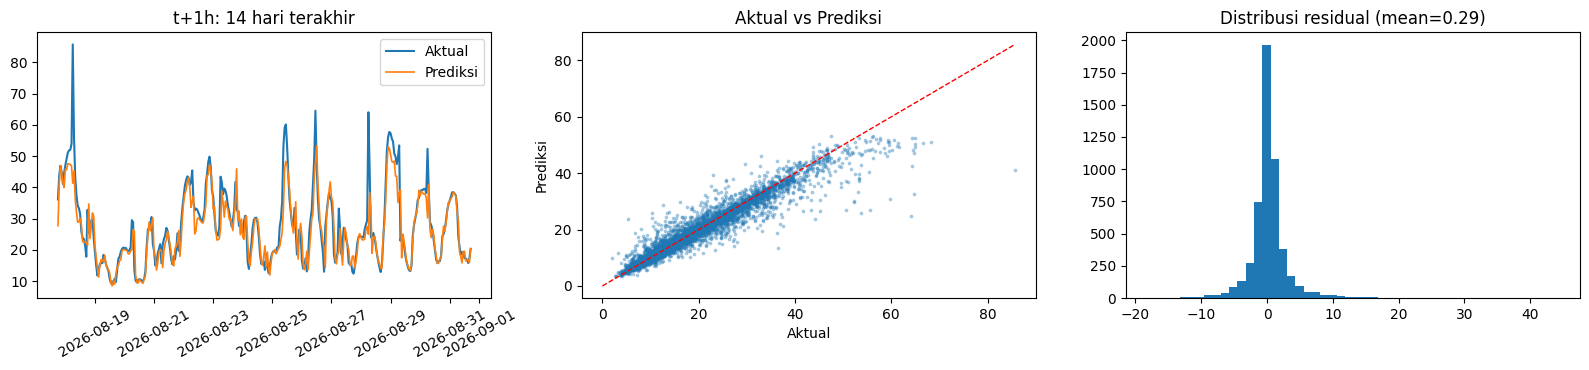

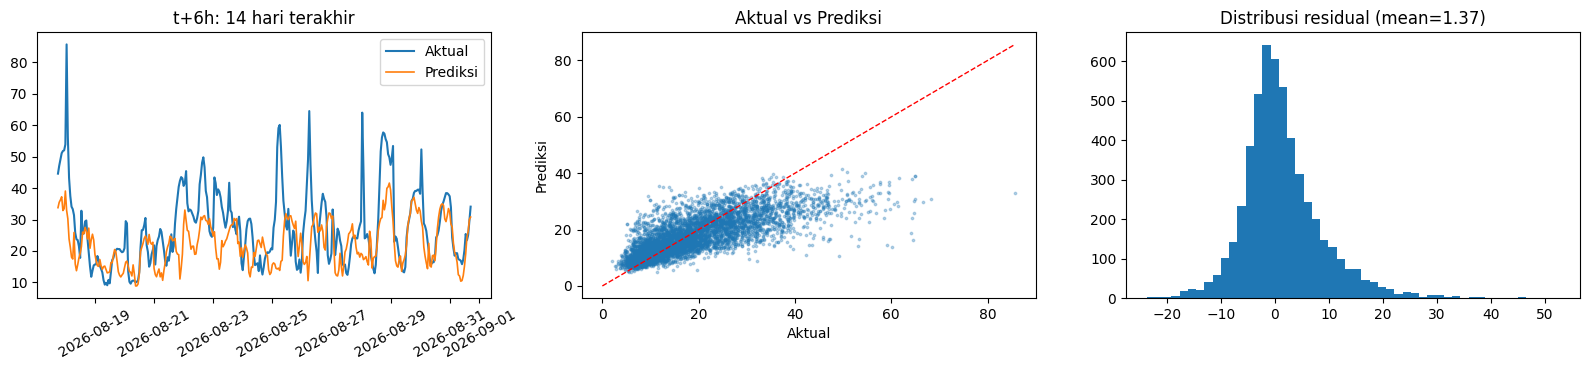

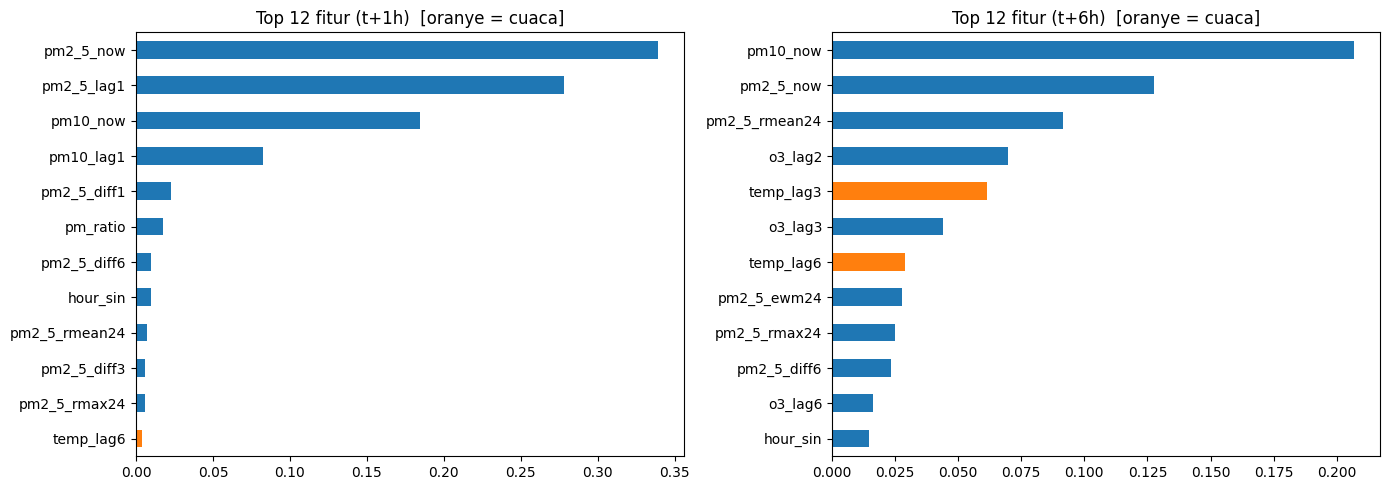

In [19]:
for h in H_PLOT:
    y = f'y_{h}h'
    cols = final_models[h]['features']; mdl = final_models[h]['XGBoost']
    pred = mdl.predict(test[cols])
    resid = test[y].values - pred

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    t = test.iloc[-24 * 14:]
    ax[0].plot(t.index, t[y], label='Aktual', lw=1.5)
    ax[0].plot(t.index, mdl.predict(t[cols]), label='Prediksi', lw=1.2)
    ax[0].set_title(f't+{h}h: 14 hari terakhir'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=30)
    ax[1].scatter(test[y], pred, s=3, alpha=0.3)
    lim = [0, max(test[y].max(), pred.max())]
    ax[1].plot(lim, lim, 'r--', lw=1)
    ax[1].set_xlabel('Aktual'); ax[1].set_ylabel('Prediksi'); ax[1].set_title('Aktual vs Prediksi')
    ax[2].hist(resid, bins=50)
    ax[2].set_title(f'Distribusi residual (mean={resid.mean():.2f})')
    plt.tight_layout(); plt.show()

# Feature importance (fitur cuaca diberi warna oranye)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, h in zip(axes, H_PLOT):
    imp = pd.Series(final_models[h]['XGBoost'].feature_importances_,
                    index=final_models[h]['features']).nlargest(12).sort_values()
    imp.plot.barh(ax=ax, color=['tab:orange' if c in COLS_CUACA else 'tab:blue' for c in imp.index],
                  title=f'Top 12 fitur (t+{h}h)  [oranye = cuaca]')
plt.tight_layout(); plt.show()

## 7. Peringatan Dini (Alarm Waspada)
Regresi PM2.5 cenderung "menarik" prediksi ke tengah sehingga lonjakan ekstrem terlewat. Karena itu ditambahkan **klasifikasi alarm**: apakah PM2.5 pada t+h akan melewati ambang **Waspada = 35 µg/m³**.

- **Kategori PM2.5** mengikuti ISPU (Permen LHK No. 14 Tahun 2020): Baik 0-15,5; Sedang 15,6-55,4; Tidak Sehat 55,5-150,4; Sangat Tidak Sehat 150,5-250,4; Berbahaya > 250,4 µg/m³.
- **Ambang Waspada 35 µg/m³ bukan angka resmi**, melainkan ambang peringatan dini internal. Ambang 55,4 (Tidak Sehat) terlalu langka di data (hanya 21 kejadian di data dev) sehingga tidak dapat dipelajari dengan andal.

**Cara kerja alarm:**
1. Klasifier XGBoost memakai fitur terpilih dari bagian 5 (per horizon).
2. **Probabilitas dikalibrasi** (isotonic) agar "peluang 40%" benar-benar berarti sekitar 40% kejadian. Tanpa kalibrasi, `scale_pos_weight` membuat angka peluang membengkak.
3. **Kalibrasi dan ambang alarm ditentukan dari prediksi out-of-fold** pada 2 fold terakhir. Fold awal hanya memuat 26-37 kejadian, sedangkan 2 fold terakhir memuat ratusan kejadian dan lebih mirip pola 2026.

In [20]:
THR_WASPADA = 35.0

def kategori_pm25(v):
    """Kategori ISPU PM2.5 (Permen LHK No. 14 Tahun 2020)."""
    if v <= 15.5:  return 'Baik'
    if v <= 55.4:  return 'Sedang'
    if v <= 150.4: return 'Tidak Sehat'
    if v <= 250.4: return 'Sangat Tidak Sehat'
    return 'Berbahaya'

REKOMENDASI = {
    'Baik': 'Kualitas udara baik. Aktivitas luar ruangan aman dilakukan.',
    'Sedang': 'Kelompok sensitif (asma, lansia, anak-anak) sebaiknya mengurangi aktivitas berat di luar ruangan.',
    'Tidak Sehat': 'Batasi aktivitas luar ruangan dan gunakan masker N95. Kelompok sensitif sebaiknya tetap di dalam ruangan.',
    'Sangat Tidak Sehat': 'Hindari aktivitas luar ruangan, gunakan masker N95, dan nyalakan penyaring udara jika ada.',
    'Berbahaya': 'Tetap di dalam ruangan dengan jendela tertutup. Cari bantuan medis jika mengalami sesak napas.',
}
REK_WASPADA = ('PERINGATAN DINI: potensi PM2.5 > 35 µg/m³. Kelompok sensitif sebaiknya mengurangi '
               'aktivitas luar ruangan dan menyiapkan masker N95.')

def peringatan_dini(nilai, horizon, alarm=False, prob=None):
    k = kategori_pm25(nilai)
    teks = f'Prediksi PM2.5 {horizon} jam ke depan: {nilai:.1f} µg/m³ ({k}). {REKOMENDASI[k]}'
    if alarm:
        teks += f' [{REK_WASPADA}' + (f' Peluang: {prob:.0%}]' if prob is not None else ']')
    return teks

In [21]:
def buat_clf(y_tr):
    spw = min((y_tr == 0).sum() / max(y_tr.sum(), 1), 20)      # penyeimbang kelas langka
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                         subsample=0.8, colsample_bytree=0.6, reg_lambda=10,
                         scale_pos_weight=spw, tree_method='hist', random_state=42, n_jobs=-1)

def pilih_ambang(y_true, skor):
    """Ambang probabilitas yang memaksimalkan F1."""
    p, r, t = precision_recall_curve(y_true, skor)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-9)
    return float(t[np.nanargmax(f1)])

# Jumlah kejadian > ambang per fold validasi (dasar pemilihan fold untuk kalibrasi dan ambang)
prev = []
for i, (a, b) in enumerate(folds, 1):
    row = {'Fold': i, 'Baris val': len(b)}
    for h in [HORIZONS[0], HORIZONS[-1]]:
        row[f'Kejadian t+{h}'] = int((dev[f'y_{h}h'].iloc[b] > THR_WASPADA).sum())
    prev.append(row)
display(pd.DataFrame(prev).set_index('Fold'))

,Baris val,Kejadian t+1,Kejadian t+6
Fold,,,
1,4942,37,37
2,4942,26,26
3,4942,26,26
4,4942,219,222
5,4942,365,365


In [22]:
FOLD_AMBANG = 'terakhir2'    # 'terakhir2' = kalibrasi/ambang dari 2 fold terakhir | 'semua' = dari 5 fold
fold_pakai = folds if FOLD_AMBANG == 'semua' else folds[-2:]

cls_models, cls_cal, cls_thr, rows = {}, {}, {}, []
for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']
    yc_dev  = (dev[y]  > THR_WASPADA).astype(int)
    yc_test = (test[y] > THR_WASPADA).astype(int)

    # prediksi out-of-fold klasifier
    oof = pd.Series(np.nan, index=dev.index)
    for a, b in fold_pakai:
        tr, va = dev.iloc[a], dev.iloc[b]
        ytr = (tr[y] > THR_WASPADA).astype(int)
        oof.iloc[b] = buat_clf(ytr).fit(tr[cols], ytr).predict_proba(va[cols])[:, 1]
    ok = oof.notna()

    # kalibrasi dan ambang dari out-of-fold
    cal = Kalibrator().fit(oof[ok].values, yc_dev[ok].values)
    thr = pilih_ambang(yc_dev[ok], cal.predict(oof[ok].values))

    # model final (dev) dievaluasi di test
    clf = buat_clf(yc_dev).fit(dev[cols], yc_dev)
    cls_models[h], cls_cal[h], cls_thr[h] = clf, cal, thr

    p_raw = clf.predict_proba(test[cols])[:, 1]; p_cal = cal.predict(p_raw)
    alarm = p_cal >= thr
    rows.append({'Horizon': h, 'Kejadian test': int(yc_test.sum()),
                 'PR-AUC': round(average_precision_score(yc_test, p_cal), 3),
                 'Brier mentah': round(brier_score_loss(yc_test, p_raw), 4),
                 'Brier kalibrasi': round(brier_score_loss(yc_test, p_cal), 4),
                 'Ambang': round(thr, 3),
                 'Recall': round(recall_score(yc_test, alarm), 2),
                 'Precision': round(precision_score(yc_test, alarm, zero_division=0), 2),
                 'Jumlah alarm': int(alarm.sum())})

hl = f'y_{HORIZONS[-1]}h'
print(f'Prevalensi kejadian > {THR_WASPADA}: dev={(dev[hl] > THR_WASPADA).mean():.1%}, '
      f'test={(test[hl] > THR_WASPADA).mean():.1%}  (selisih = pergeseran pola 2026)')
alarm_df = pd.DataFrame(rows).set_index('Horizon')
display(alarm_df)

Prevalensi kejadian > 35.0: dev=2.4%, test=8.8%  (selisih = pergeseran pola 2026)


,Kejadian test,PR-AUC,Brier mentah,Brier kalibrasi,Ambang,Recall,Precision,Jumlah alarm
Horizon,,,,,,,,
1,463,0.900,0.0314,0.0245,0.449,0.95,0.69,645
2,463,0.771,0.0578,0.0412,0.406,0.86,0.55,718
3,463,0.647,0.0771,0.0531,0.333,0.74,0.51,673
4,462,0.581,0.0919,0.0625,0.290,0.83,0.36,1075
5,461,0.454,0.1073,0.0692,0.300,0.77,0.33,1072
6,460,0.432,0.1165,0.0714,0.221,0.77,0.29,1198


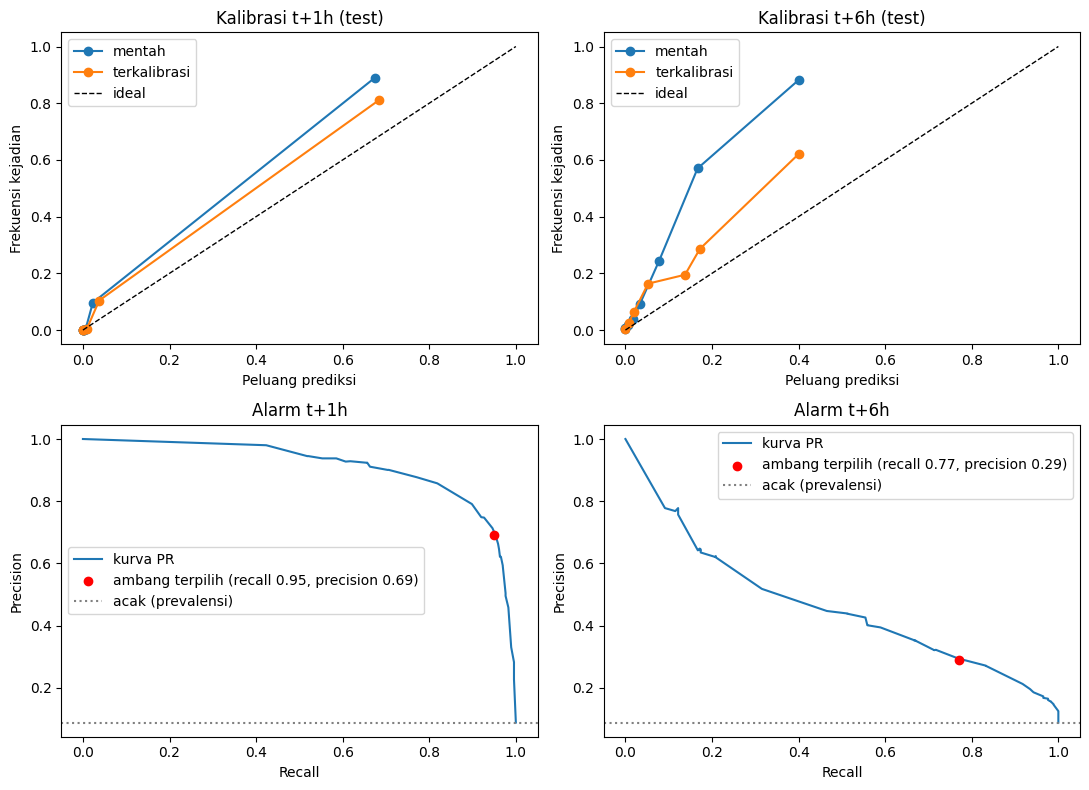

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for j, h in enumerate(H_PLOT):
    y = f'y_{h}h'; cols = final_models[h]['features']
    yc = (test[y] > THR_WASPADA).astype(int)
    p_raw = cls_models[h].predict_proba(test[cols])[:, 1]
    p_cal = cls_cal[h].predict(p_raw)

    # (atas) kalibrasi: peluang prediksi vs frekuensi kejadian sebenarnya
    a_ = ax[0, j]
    for p, lab in [(p_raw, 'mentah'), (p_cal, 'terkalibrasi')]:
        fx, fy = calibration_curve(yc, p, n_bins=8, strategy='quantile')[::-1]
        a_.plot(fy, fx, 'o-', label=lab)
    a_.plot([0, 1], [0, 1], 'k--', lw=1, label='ideal')
    a_.set_title(f'Kalibrasi t+{h}h (test)'); a_.set_xlabel('Peluang prediksi'); a_.set_ylabel('Frekuensi kejadian'); a_.legend()

    # (bawah) trade-off recall vs precision pada ambang terpilih
    a_ = ax[1, j]
    pr, rc, _ = precision_recall_curve(yc, p_cal)
    a_.plot(rc, pr, label='kurva PR')
    r_, p_ = alarm_df.loc[h, 'Recall'], alarm_df.loc[h, 'Precision']
    a_.scatter([r_], [p_], c='r', zorder=3, label=f'ambang terpilih (recall {r_:.2f}, precision {p_:.2f})')
    a_.axhline(yc.mean(), color='gray', ls=':', label='acak (prevalensi)')
    a_.set_xlabel('Recall'); a_.set_ylabel('Precision'); a_.set_title(f'Alarm t+{h}h'); a_.legend()
plt.tight_layout(); plt.show()

## 8. Finalisasi Model & Penyimpanan
Setelah evaluasi di data test selesai (angka di atas **tidak diubah lagi**), model dilatih ulang pada **seluruh data (dev + test)** supaya dashboard memakai pola terbaru, termasuk periode 2026.

- Jumlah pohon regresi = iterasi terbaik early stopping × 1,15 (data bertambah ± 18%).
- Fitur, kalibrator, dan ambang alarm **tidak diubah** (berasal dari data dev).
- Metrik yang disimpan di `meta` adalah metrik **test dari model sebelum dilatih ulang**.

Disimpan: model regresi, klasifier alarm, kalibrator, ambang, dan daftar fitur untuk tiap horizon.

In [24]:
reg_save, cls_save = {}, {}
for h in HORIZONS:
    y = f'y_{h}h'; cols = final_models[h]['features']
    params = {k: v for k, v in XGB_FINAL.items() if k != 'early_stopping_rounds'}
    params['n_estimators'] = int((final_models[h]['XGBoost'].best_iteration + 1) * 1.15)
    reg_save[h] = XGBRegressor(**params).fit(data[cols], data[y])
    yc_all = (data[y] > THR_WASPADA).astype(int)
    cls_save[h] = buat_clf(yc_all).fit(data[cols], yc_all)
print('Model dilatih ulang pada seluruh data:', data.index.min(), '->', data.index.max())

Model dilatih ulang pada seluruh data: 2022-09-08 00:00:00 -> 2026-08-31 17:00:00


In [25]:
meta = {
    'versi_notebook': 'v4',
    'horizons': HORIZONS,
    'features_per_horizon': {h: final_models[h]['features'] for h in HORIZONS},
    'kolom_input': POLUTAN + CUACA,             # kolom yang harus ada pada riwayat input dashboard
    'thr_waspada': THR_WASPADA,
    'ambang_alarm_prob': cls_thr,               # berlaku untuk probabilitas TERKALIBRASI
    'ambang_kategori': [15.5, 55.4, 150.4, 250.4],
    'min_riwayat': MIN_RIWAYAT,
    'periode_dev': (str(dev.index.min()), str(dev.index.max())),
    'periode_latih_final': (str(data.index.min()), str(data.index.max())),
    'metrik_test': res_df[res_df.Model == 'XGBoost (final)'].round(3).to_dict('records'),
    'alarm_test': alarm_df.reset_index().to_dict('records'),
}
joblib.dump({'reg_models': reg_save, 'cls_models': cls_save, 'cls_cal': cls_cal, 'meta': meta},
            'model_pm25.joblib', compress=3)
print('Tersimpan: model_pm25.joblib |', round(os.path.getsize('model_pm25.joblib') / 1e6, 1), 'MB')
print('File yang harus dibawa ke dashboard: model_pm25.joblib dan fitur.py')

Tersimpan: model_pm25.joblib | 1.9 MB
File yang harus dibawa ke dashboard: model_pm25.joblib dan fitur.py


## 9. Uji Integrasi Sistem
Dua pemeriksaan sebelum model dihubungkan ke dashboard:
1. **Konsistensi pelatihan vs inferensi:** fitur yang dihitung dari potongan riwayat (seperti di dashboard) harus sama dengan fitur yang dipakai saat pelatihan.
2. **Prediksi end-to-end** dari file `.joblib`.

In [26]:
# 1) Fitur dari riwayat 300 jam harus sama dengan fitur penuh pada jam yang sama
for akhir in [len(df), len(df) - 500, len(df) - 5000]:
    pot = df.iloc[akhir - 300:akhir]
    selisih = (buat_fitur(pot).iloc[-1] - feat.iloc[akhir - 1]).abs().max()
    print(f'Jam {pot.index[-1]} | selisih fitur maksimum = {selisih:.2e}')
    assert selisih < 1e-3, 'Fitur inferensi berbeda dari fitur pelatihan!'
print('OK: fitur inferensi identik dengan fitur pelatihan.')

Jam 2026-08-31 23:00:00 | selisih fitur maksimum = 3.70e-11
Jam 2026-08-11 03:00:00 | selisih fitur maksimum = 4.93e-11
Jam 2026-02-04 15:00:00 | selisih fitur maksimum = 3.14e-10
OK: fitur inferensi identik dengan fitur pelatihan.


In [27]:
# 2) Muat dari file lalu prediksi dari riwayat, seperti yang akan dilakukan dashboard
sys.modules.pop('fitur', None)
from fitur import buat_fitur, Kalibrator                      # Kalibrator diperlukan joblib saat memuat model
paket = joblib.load('model_pm25.joblib')
RM, CM, CAL, meta_load = paket['reg_models'], paket['cls_models'], paket['cls_cal'], paket['meta']

def prediksi_dini(riwayat):
    """riwayat: DataFrame indeks waktu per jam, kolom sesuai meta['kolom_input'], minimal 200 jam."""
    kurang = [c for c in meta_load['kolom_input'] if c not in riwayat.columns]
    if kurang:
        raise ValueError(f'Kolom input kurang: {kurang}')
    if len(riwayat) < meta_load['min_riwayat']:
        raise ValueError(f"Riwayat minimal {meta_load['min_riwayat']} jam, diterima {len(riwayat)}.")
    if riwayat[meta_load['kolom_input']].tail(meta_load['min_riwayat']).isna().any().any():
        raise ValueError('Ada nilai kosong pada 200 jam terakhir.')
    fitur_all = buat_fitur(riwayat).iloc[[-1]]
    hasil = {}
    for h in meta_load['horizons']:
        x = fitur_all[meta_load['features_per_horizon'][h]]
        nilai = max(float(RM[h].predict(x)[0]), 0.0)
        prob  = float(CAL[h].predict(CM[h].predict_proba(x)[:, 1])[0])      # probabilitas terkalibrasi
        alarm = prob >= meta_load['ambang_alarm_prob'][h]
        hasil[h] = {'nilai': nilai, 'kategori': kategori_pm25(nilai), 'prob_waspada': prob,
                    'alarm': alarm, 'pesan': peringatan_dini(nilai, h, alarm, prob)}
    return hasil

keluaran = prediksi_dini(df.iloc[-300:])      # simulasi: 300 jam data terakhir
for h, r in keluaran.items():
    print(f"t+{h}h  {r['nilai']:5.1f} µg/m³  {r['kategori']:<7} peluang>35: {r['prob_waspada']:4.0%}  alarm={r['alarm']}")
print()
print(keluaran[HORIZONS[-1]]['pesan'])

t+1h   36.0 µg/m³  Sedang  peluang>35:  83%  alarm=True
t+2h   36.5 µg/m³  Sedang  peluang>35:  84%  alarm=True
t+3h   36.4 µg/m³  Sedang  peluang>35:  63%  alarm=True
t+4h   35.2 µg/m³  Sedang  peluang>35:  66%  alarm=True
t+5h   33.4 µg/m³  Sedang  peluang>35:  76%  alarm=True
t+6h   34.3 µg/m³  Sedang  peluang>35:  64%  alarm=True

Prediksi PM2.5 6 jam ke depan: 34.3 µg/m³ (Sedang). Kelompok sensitif (asma, lansia, anak-anak) sebaiknya mengurangi aktivitas berat di luar ruangan. [PERINGATAN DINI: potensi PM2.5 > 35 µg/m³. Kelompok sensitif sebaiknya mengurangi aktivitas luar ruangan dan menyiapkan masker N95. Peluang: 64%]


> **Untuk dashboard:** data terbaru perlu diambil dari API Open-Meteo versi *forecast* (parameter `past_days`), karena API arsip punya jeda beberapa hari. Perhatikan bahwa air-quality API pada mode ini berisi prakiraan CAMS, bukan reanalisis seperti data latih, sehingga akurasi di dashboard bisa sedikit berbeda dari angka test. Pengambilan data ini dikerjakan di sisi dashboard (Streamlit).

## 10. Ringkasan untuk Laporan (Progress Report 2)
Tabel di bawah dihasilkan otomatis dari hasil eksekusi. Salin angkanya ke laporan agar konsisten dengan notebook.

In [28]:
print('=== (a) Kontribusi fitur cuaca (RMSE, µg/m³) ===')
display(ablation[['CV A (mean)', 'CV B (mean)', 'Fold B menang', 'Test A', 'Test B',
                  'Selisih test (B-A)', 'Perbaikan test (%)']].round(3))

print('=== (b) Metrik test model final ===')
display(final)

print('=== (c) Alarm Waspada (data test) ===')
display(alarm_df[['Kejadian test', 'PR-AUC', 'Ambang', 'Recall', 'Precision', 'Jumlah alarm',
                  'Brier mentah', 'Brier kalibrasi']])

ablation.round(4).to_csv('hasil_cuaca.csv'); final.to_csv('hasil_test_final.csv'); alarm_df.to_csv('hasil_alarm.csv')
print('Tersimpan: hasil_cuaca.csv, hasil_test_final.csv, hasil_alarm.csv')

=== (a) Kontribusi fitur cuaca (RMSE, µg/m³) ===


,CV A (mean),CV B (mean),Fold B menang,Test A,Test B,Selisih test (B-A),Perbaikan test (%)
Horizon,,,,,,,
1,2.106,2.090,3/5,3.119,3.162,0.043,-1.367
2,3.148,3.091,4/5,4.708,4.617,-0.091,1.940
3,3.857,3.767,4/5,5.708,5.620,-0.088,1.544
4,4.448,4.354,3/5,6.480,6.390,-0.090,1.384
5,4.922,4.842,3/5,7.127,7.065,-0.062,0.869
6,5.347,5.179,4/5,7.614,7.521,-0.093,1.222


=== (b) Metrik test model final ===


,RMSE,MAE,R2
Horizon,,,
1,3.162,1.774,0.913
2,4.617,2.898,0.815
3,5.620,3.726,0.726
4,6.390,4.346,0.646
5,7.065,4.891,0.567
6,7.521,5.276,0.509


=== (c) Alarm Waspada (data test) ===


,Kejadian test,PR-AUC,Ambang,Recall,Precision,Jumlah alarm,Brier mentah,Brier kalibrasi
Horizon,,,,,,,,
1,463,0.900,0.449,0.95,0.69,645,0.0314,0.0245
2,463,0.771,0.406,0.86,0.55,718,0.0578,0.0412
3,463,0.647,0.333,0.74,0.51,673,0.0771,0.0531
4,462,0.581,0.290,0.83,0.36,1075,0.0919,0.0625
5,461,0.454,0.300,0.77,0.33,1072,0.1073,0.0692
6,460,0.432,0.221,0.77,0.29,1198,0.1165,0.0714


Tersimpan: hasil_cuaca.csv, hasil_test_final.csv, hasil_alarm.csv


### Eksperimen yang dicoba dan tidak dipakai
- **Tuning hyperparameter** (random search 12 kombinasi per horizon: `max_depth`, `min_child_weight`, `subsample`, `colsample_bytree`, `reg_lambda`, `reg_alpha`, `gamma`, dengan TimeSeriesSplit): perbaikan RMSE CV terbaik hanya 0-0,95%, di bawah batas 1% dan lebih kecil daripada simpangan baku antar fold. Konfigurasi awal dipertahankan.
- **Pembobotan waktu** (data baru diberi bobot lebih besar dengan half-life 365, 180, dan 90 hari): tidak memberi perbaikan yang konsisten pada RMSE CV, sehingga tidak dipakai.
- **Gabungan regresi dan klasifier untuk alarm** (alarm bila salah satu atau keduanya melewati ambang): tidak dipakai agar logika dashboard tetap sederhana, cukup klasifier terkalibrasi.

### Checklist isi laporan
1. **Validasi:** K-Fold biasa tidak dipakai karena bocor (acak merusak autokorelasi), diganti TimeSeriesSplit 5 fold dengan `gap=6`.
2. **Fitur cuaca:** tabel (a) di atas. Tulis perbaikannya apa adanya (kecil tetapi konsisten, bukan faktor dominan) beserta porsi importance fitur cuaca (bagian 5.3).
3. **Kualitas model:** akurasi turun seiring horizon (lihat R² di tabel (b)). Model unggul dari Persistence, tetapi horizon yang lebih jauh makin lemah.
4. **Alarm:** tabel (c), jelaskan trade-off recall vs precision dan jumlah alarm. Ambang Waspada 35 µg/m³ adalah ambang internal, bukan angka resmi.
5. **Keterbatasan:** pergeseran pola 2026 (prevalensi kejadian > 35 di test lebih tinggi dari dev), kejadian ekstrem langka, data reanalisis satu titik, selisih koordinat cuaca dan polutan ± 2,4 km, serta data dashboard (prakiraan CAMS) berbeda dari data latih (reanalisis).